# 01. Text Preprocessing & Corpus Exploration

Comprehensive exploratory analysis of raw versus normalized achievement text, evaluating Unicode normalization, whitespace collapsing, text casing tradeoffs, tokenization properties, and text length distributions.

**Dataset Release:** `achievement_dataset_v1.0.1` | **Author:** Member 1 (NLP & Semantic Intelligence Engineer)

## 1. Environment & Module Imports
We import essential analysis libraries alongside our production preprocessing module `nlp.text_preprocessing`.

In [1]:
import sys
import re
import unicodedata
from pathlib import Path

# Ensure src is on sys.path regardless of execution working directory
repo_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
src_path = str(repo_root / "src")
if src_path not in sys.path:
    sys.path.insert(0, src_path)

import pandas as pd
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

from nlp.text_preprocessing import (
    normalize_unicode,
    normalize_whitespace,
    normalize_text_for_classification,
    compare_preprocessing_outputs,
    tokenize_words,
    preprocess_dataframe
)

print("Environment and preprocessing module successfully imported.")

Environment and preprocessing module successfully imported.


## 2. Dataset Loading
We load the frozen `achievement_dataset_v1.0.1` (`achievement_classification_dataset.csv`, 1,540 records) and inspect the primary text columns.

In [2]:
data_path = REPO_ROOT / "data" / "processed" / "achievement_classification_dataset.csv"
df = pd.read_csv(data_path)

print(f"Loaded Primary Dataset: {df.shape[0]} rows, {df.shape[1]} columns.")
display_cols = ["achievement_id", "category", "achievement_text", "normalized_text"]
print(df[display_cols].head(3).to_string())

Loaded Primary Dataset: 1540 rows, 26 columns.
  achievement_id category                                                                                                                                                                                                                                                                                                                           achievement_text                                                                                                                                                                                                                                                                                                                            normalized_text
0      ACH000402   PATENT  Co-inventor on patent application #2021553873 filed with the United States Patent and Trademark Office (USPTO): 'An Adaptive Impedance-Matching System for Wireless Power Transfer in Implantable Medical Devices'. Engineered sensor hardware

## 3. Investigating `achievement_text` vs `normalized_text`
We evaluate whether the existing dataset fields differ in release `v1.0.1` and document why they are currently aligned.

In [3]:
diff_count = (df["achievement_text"] != df["normalized_text"]).sum()
print(f"Total dataset records: {len(df)}")
print(f"Records where achievement_text != normalized_text: {diff_count}")

# Check characteristics of both fields
sample = df.iloc[0]
print("\nRepresentative Sample (ACH000001):")
print("Raw achievement_text: ", repr(sample["achievement_text"][:100]))
print("normalized_text:     ", repr(sample["normalized_text"][:100]))
print("\nFinding: In v1.0.1, normalized_text was constructed using standard NFC Unicode normalization and whitespace trimming, preserving full capitalization and punctuation.")

Total dataset records: 1540
Records where achievement_text != normalized_text: 0

Representative Sample (ACH000001):
Raw achievement_text:  'Co-inventor on patent application #2021553873 filed with the United States Patent and Trademark Offi'
normalized_text:      'Co-inventor on patent application #2021553873 filed with the United States Patent and Trademark Offi'

Finding: In v1.0.1, normalized_text was constructed using standard NFC Unicode normalization and whitespace trimming, preserving full capitalization and punctuation.


## 4. Unicode Normalization Exploration
We evaluate Canonical Composition (`NFC`) versus Compatibility Decomposition (`NFKC`) across various text types including ASCII, accented letters, Unicode quotes, mathematical symbols, and non-English scripts.

In [4]:
test_cases = [
    ("ASCII Text", "Won 1st place in Smart India Hackathon 2023."),
    ("Accented Latin", "Residénce d'étudiant: première place"),
    ("Unicode Punctuation", "“Winner” at National AI Summit — Team Lead"),
    ("Devanagari Script", "रोबोटिक्स प्रतियोगिता २०२३"),
    ("Tamil Script", "கணிப்பொறி அறிவியல் மாநாடு"),
    ("Compatibility Numerals", "Grade: １００% secured in examination")
]

print(f"{'Input Type':<25} | {'Original Text':<45} | {'NFC Normalization':<45} | {'NFKC Normalization'}")
print("-" * 140)
for name, raw in test_cases:
    nfc = normalize_unicode(raw, form="NFC")
    nfkc = normalize_unicode(raw, form="NFKC")
    print(f"{name:<25} | {raw:<45} | {nfc:<45} | {nfkc}")

print("\nObservation: NFC preserves visual representation and accents, while NFKC normalizes full-width numerals into standard ASCII digits.")

Input Type                | Original Text                                 | NFC Normalization                             | NFKC Normalization
--------------------------------------------------------------------------------------------------------------------------------------------
ASCII Text                | Won 1st place in Smart India Hackathon 2023.  | Won 1st place in Smart India Hackathon 2023.  | Won 1st place in Smart India Hackathon 2023.
Accented Latin            | Residénce d'étudiant: première place          | Residénce d'étudiant: première place          | Residénce d'étudiant: première place
Unicode Punctuation       | “Winner” at National AI Summit — Team Lead    | “Winner” at National AI Summit — Team Lead    | “Winner” at National AI Summit — Team Lead
Devanagari Script         | रोबोटिक्स प्रतियोगिता २०२३                    | रोबोटिक्स प्रतियोगिता २०२३                    | रोबोटिक्स प्रतियोगिता २०२३
Tamil Script              | கணிப்பொறி அறிவியல் மாநாடு               

## 5. Whitespace Normalization
We demonstrate how consecutive spaces, tabs, newlines, and non-breaking spaces are collapsed while preserving valid intra-sentence punctuation.

In [5]:
raw_whitespace_sample = "   Spearheaded   the project team \t\t at SIH 2024.\n\nDelivered a validated prototype.\u00A0\u200B  "
cleaned_ws = normalize_whitespace(raw_whitespace_sample)

print("Original text with erratic whitespace:")
print(repr(raw_whitespace_sample))
print("\nAfter normalize_whitespace:")
print(repr(cleaned_ws))

diag = compare_preprocessing_outputs(raw_whitespace_sample, cleaned_ws)
print("\nDiagnostic Summary:", diag)

Original text with erratic whitespace:
'   Spearheaded   the project team \t\t at SIH 2024.\n\nDelivered a validated prototype.\xa0\u200b  '

After normalize_whitespace:
'Spearheaded the project team at SIH 2024. Delivered a validated prototype.'

Diagnostic Summary: {'original_length': 87, 'processed_length': 74, 'length_difference': -13, 'original_words': 11, 'processed_words': 11, 'words_difference': 0, 'case_changed': False, 'whitespace_collapsed': True, 'is_identical': False}


## 6. Text Casing Tradeoff Analysis
We compare lowercasing versus preserving original case. Lowercasing assists TF-IDF vocabulary compaction, whereas uppercase letters are critical for identifying acronyms (AWS, SIH, IEEE, ROS-2) and exact skill matches.

In [6]:
sample_text = "Spearheaded 3-person team for AWS Cloud & IEEE Conference paper on ROS-2."
cased_lower = normalize_text_for_classification(sample_text, lowercase=True)
cased_orig = normalize_text_for_classification(sample_text, lowercase=False)

print("Original Cased:     ", cased_orig)
print("Lowercased Version: ", cased_lower)
print("\nRecommendation: Use lowercasing for TF-IDF classification; strictly preserve original casing for Skill Extraction and Sentence Transformer bi-encoders.")

Original Cased:      Spearheaded 3-person team for AWS Cloud & IEEE Conference paper on ROS-2.
Lowercased Version:  spearheaded 3-person team for aws cloud & ieee conference paper on ros-2.

Recommendation: Use lowercasing for TF-IDF classification; strictly preserve original casing for Skill Extraction and Sentence Transformer bi-encoders.


## 7. Word Tokenization & N-Gram Extraction
We test our tokenization pattern on technical achievements containing hyphenated compounds, numbers, and dates.

In [7]:
tech_text = "Won 1st-place in the 48-hour hackathon, engineering a real-time ROS-2 pipeline using PyTorch-v2.0."
tokens = tokenize_words(tech_text, lowercase=True, remove_stopwords=False)
tokens_no_sw = tokenize_words(tech_text, lowercase=True, remove_stopwords=True)

print("All extracted tokens:")
print(tokens)
print("\nTokens after stopword removal:")
print(tokens_no_sw)

All extracted tokens:
['won', '1st-place', 'in', 'the', '48-hour', 'hackathon', 'engineering', 'a', 'real-time', 'ros-2', 'pipeline', 'using', 'pytorch-v2', '0']

Tokens after stopword removal:
['won', '1st-place', '48-hour', 'hackathon', 'engineering', 'real-time', 'ros-2', 'pipeline', 'using', 'pytorch-v2', '0']


## 8. Text Length & Word Count Distributions
We compute character and word statistics across the primary dataset and plot their distributions.

Character Length: Min = 142, Mean = 256.5, Median = 255.0, Max = 417
Word Count:       Min = 20, Mean = 33.1, Median = 33.0, Max = 56


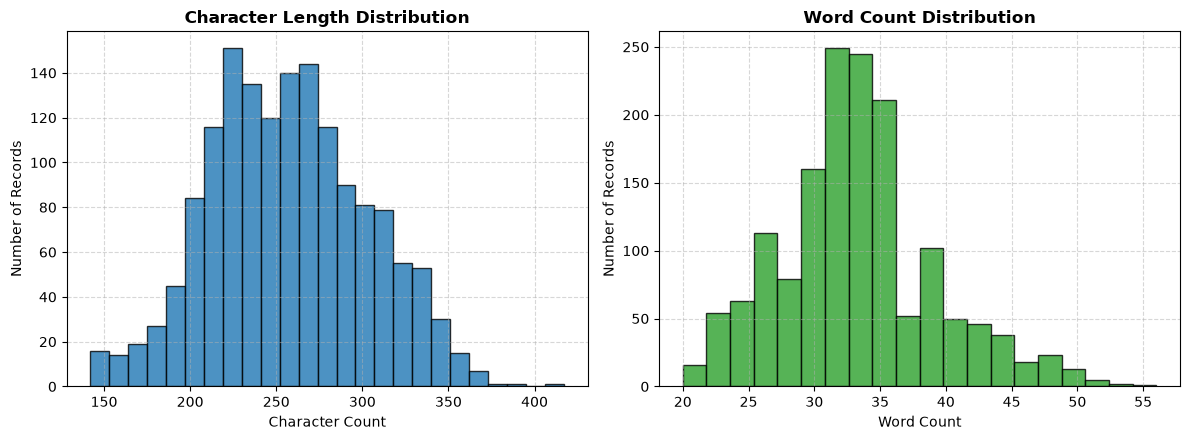

In [8]:
char_lengths = df["achievement_text"].apply(len)
word_counts = df["achievement_text"].apply(lambda t: len(t.split()))

print(f"Character Length: Min = {char_lengths.min()}, Mean = {char_lengths.mean():.1f}, Median = {char_lengths.median()}, Max = {char_lengths.max()}")
print(f"Word Count:       Min = {word_counts.min()}, Mean = {word_counts.mean():.1f}, Median = {word_counts.median()}, Max = {word_counts.max()}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

ax1.hist(char_lengths, bins=25, color="#1f77b4", edgecolor="black", alpha=0.8)
ax1.set_title("Character Length Distribution", fontsize=12, fontweight="bold")
ax1.set_xlabel("Character Count")
ax1.set_ylabel("Number of Records")
ax1.grid(True, linestyle="--", alpha=0.5)

ax2.hist(word_counts, bins=20, color="#2ca02c", edgecolor="black", alpha=0.8)
ax2.set_title("Word Count Distribution", fontsize=12, fontweight="bold")
ax2.set_xlabel("Word Count")
ax2.set_ylabel("Number of Records")
ax2.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()

## 9. Exploration Summary & Conclusions
- **Unicode:** NFC is optimal as the global default; NFKC is beneficial in duplicate detection to normalize full-width numbers.
- **Whitespace:** Stripping leading/trailing spaces and collapsing internal multi-spaces standardizes all records.
- **Decoupled Architecture:** One-size-fits-all preprocessing is rejected. Task-specific pipelines are essential.